In [ ]:
# 1. Desinstala versões inconsistentes do OpenCV
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python

# 2. Instala a versão estável compatível do OpenCV
!pip install opencv-python-headless==4.10.0.84

# 3. Força a reinicialização dos pacotes carregados em memória
import sys
if 'cv2' in sys.modules:
    del sys.modules['cv2']


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 39.4 MB/s  0:00:01


In [ ]:
!pip install face_recognition

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 50.7 MB/s  0:00:02
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=cf0b5b8e84e7139d116d5212d3dde81be77704a120093889da525b0d786ce79f
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face_recognition]


In [ ]:
import cv2    #OpenCV (Haar Cascade): Apenas encontra onde está o rosto na foto (detecção).
import numpy as np
import face_recognition #face_recognition: Identifica quem é a pessoa(reconhecimento).
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt

print("Bibliotecas importadas com sucesso!")

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Bibliotecas importadas com sucesso!


In [ ]:
print("Carregando o dataset LFW...")

# Filtra pessoas com pelo menos 20 imagens registradas
lfw_people = fetch_lfw_people(min_faces_per_person=20, resize=1.0, color=True)

images = lfw_people.images  # Array de imagens RGB
names = lfw_people.target_names  # Rótulos (nomes das pessoas)
labels = lfw_people.target  # Vetor numérico com as classes

print(f"Total de imagens carregadas: {len(images)}")
print(f"Número de classes (pessoas distintas): {len(names)}")

Carregando o dataset LFW...
Total de imagens carregadas: 3023
Número de classes (pessoas distintas): 62


In [ ]:
import os
import urllib.request   #Ele prepara o detector de rostos do OpenCV antes de você procurar rostos nas imagens do dataset LFW:

xml_filename = "haarcascade_frontalface_default.xml"
if not os.path.exists(xml_filename):
    xml_url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"
    urllib.request.urlretrieve(xml_url, xml_filename)

face_cascade = cv2.CascadeClassifier(xml_filename) #algortimo ML

if face_cascade.empty():
    print("Erro ao carregar o classificador Haar Cascade!")
else:
    print("Haar Cascade carregado com sucesso!")

Haar Cascade carregado com sucesso!


In [ ]:
known_face_encodings = []    #Esse trecho cria o banco de dados de referência do sistema. Ele percorre as fotos do dataset LFW, extrai a "assinatura matemática" (chamada de embedding) do rosto de cada pessoa e salva apenas um exemplo válido por indivíduo para ser usado como comparação no futuro
known_face_names = []
registered_persons = set()

print("A gerar embeddings de referência...")

for i, img in enumerate(images):
    person_name = names[labels[i]]

    # Cadastra apenas a primeira ocorrência válida de cada pessoa
    if person_name not in registered_persons:
        img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)

        # Gera o embedding
        encodings = face_recognition.face_encodings(img_uint8)

        if len(encodings) > 0:
            known_face_encodings.append(encodings[0])
            known_face_names.append(person_name)
            registered_persons.add(person_name)

print(f"Banco de dados cadastrado com {len(known_face_encodings)} pessoas.")

A gerar embeddings de referência...
Banco de dados cadastrado com 62 pessoas.


In [ ]:
#Essa função reúne tudo o que você preparou nas etapas anteriores em um fluxo completo: ela recebe uma imagem, encontra os rostos, descobre quem são comparando com o banco de dados e desenha o resultado na foto

def process_and_recognize(image_rgb):
    # Converte para escala de cinza para o Haar Cascade
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    # Detecção do rosto com Haar Cascade #algotimo 2
    faces_detected = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
    )

    # Cópia contígua da imagem para desenhar
    output_img = image_rgb.copy()

    for (x, y, w, h) in faces_detected:
        # Recorta a Região de Interesse (ROI) e garante contiguidade em memória
        face_roi = np.ascontiguousarray(image_rgb[y:y+h, x:x+w])

        # Calcula o embedding
        # [CORRIGIDO] Passa a imagem inteira + a posição que o Haar encontrou (top, right, bottom, left).
        # Antes, o recorte apertado fazia a biblioteca não achar o rosto de novo e devolver "Desconhecido".
        encodings = face_recognition.face_encodings(image_rgb, known_face_locations=[(y, x + w, y + h, x)])  # deeplearn

        name = "Desconhecido"
        if len(encodings) > 0:
            face_encoding = encodings[0]

            # Compara o embedding atual com o banco cadastrado
            matches = face_recognition.compare_faces(known_face_encodings, face_encoding, tolerance=0.6)
            # [CORRIGIDO] O comentário estava engolindo os argumentos; agora a função é realmente chamada
            face_distances = face_recognition.face_distance(known_face_encodings, face_encoding)  # Algoritmo 3

            if len(face_distances) > 0:
                best_match_index = np.argmin(face_distances)
                if matches[best_match_index]:
                    name = known_face_names[best_match_index]

        # Desenha a caixa delimitadora e o nome identificado
        cv2.rectangle(output_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(output_img, name, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    return output_img

print("Função atualizada e registada com sucesso!")

Função atualizada e registada com sucesso!


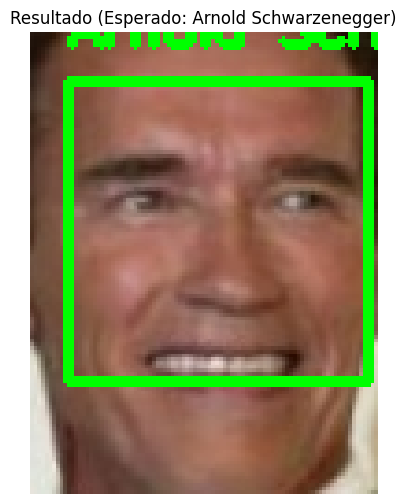

In [ ]:
# Seleciona um índice de imagem para teste
test_idx = 31

# Prepara a imagem no formato uint8
test_image = (images[test_idx] * 255).astype(np.uint8) if images[test_idx].max() <= 1.0 else images[test_idx].astype(np.uint8)

# Executa o pipeline de detecção + reconhecimento
result_image = process_and_recognize(test_image)

# Exibe o resultado na tela
plt.figure(figsize=(6, 6))
plt.imshow(result_image)
plt.title(f"Resultado (Esperado: {names[labels[test_idx]]})")
plt.axis('off')
plt.show()

# 📷 Reconhecimento facial em tempo real com a webcam

O Colab roda num servidor do Google, então o Python **não enxerga a câmera do seu computador**. A solução:

1. Um **JavaScript** roda no seu navegador, abre a webcam e captura os quadros.
2. Cada quadro é enviado ao Python como imagem base64 (via `google.colab.output.eval_js`).
3. O Python detecta e reconhece os rostos e devolve uma **camada transparente** com as caixas e os nomes, que o navegador desenha por cima do vídeo.

**Ordem de execução:** rode todas as células acima (dataset + banco de referência) → **Célula A** (funções da câmera) → **Célula B** (cadastra você) → **Célula C** (vídeo ao vivo).

> O Chrome vai pedir permissão para usar a câmera. A velocidade fica em ~2–5 quadros/s, porque cada quadro vai até o servidor e volta.

In [ ]:
# ===== CÉLULA A: funções de acesso à webcam (JavaScript <-> Python) =====
import io, json
import numpy as np        # importados aqui também, para a célula não depender das de cima
import cv2
import face_recognition
import PIL.Image
from base64 import b64decode, b64encode
from IPython.display import display, Javascript
from google.colab.output import eval_js

def js_to_image(data_url):
    """Converte o dataURL (base64) vindo do navegador em imagem RGB numpy."""
    img_bytes = b64decode(data_url.split(',')[1])
    return np.array(PIL.Image.open(io.BytesIO(img_bytes)).convert('RGB'))

def overlay_to_dataurl(overlay_rgba):
    """Converte a camada transparente (RGBA) em PNG base64 para o navegador."""
    buf = io.BytesIO()
    PIL.Image.fromarray(overlay_rgba, 'RGBA').save(buf, format='png')
    return 'data:image/png;base64,' + b64encode(buf.getvalue()).decode()

def take_photo(quality=0.8):
    """Abre a câmera, espera o clique em 'Capturar' e devolve a foto (RGB)."""
    display(Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const btn = document.createElement('button');
      btn.textContent = 'Capturar';
      const video = document.createElement('video');
      video.style.display = 'block';
      div.appendChild(video); div.appendChild(btn);
      document.body.appendChild(div);
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise(resolve => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(t => t.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }'''))
    return js_to_image(eval_js(f'takePhoto({quality})'))

def start_video_stream():
    """Cria o player de vídeo com uma camada transparente por cima para as caixas."""
    display(Javascript('''
    var video = null, div = null, stream = null, canvas = null,
        overlay = null, label = null, stopped = false;

    async function setup() {
      if (div !== null) return;
      div = document.createElement('div');
      label = document.createElement('div');
      label.style.fontWeight = 'bold';
      label.innerText = 'Iniciando...';
      div.appendChild(label);
      const box = document.createElement('div');
      box.style.position = 'relative';
      box.style.width = '640px'; box.style.height = '480px';
      video = document.createElement('video');
      video.width = 640; video.height = 480;
      video.style.objectFit = 'fill';
      video.setAttribute('playsinline', '');
      overlay = document.createElement('img');
      overlay.style.position = 'absolute';
      overlay.style.left = '0'; overlay.style.top = '0';
      overlay.style.width = '640px'; overlay.style.height = '480px';
      box.appendChild(video); box.appendChild(overlay);
      div.appendChild(box);
      const btn = document.createElement('button');
      btn.innerText = 'Parar';
      btn.onclick = () => { stopped = true; };
      div.appendChild(btn);
      document.body.appendChild(div);
      stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
      video.srcObject = stream;
      await video.play();
      canvas = document.createElement('canvas');
      canvas.width = 640; canvas.height = 480;
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
    }

    function teardown() {
      stream.getTracks().forEach(t => t.stop());
      div.remove();
      video = div = stream = canvas = overlay = label = null;
      stopped = false;
    }

    async function stream_frame(text, overlayData) {
      await setup();
      if (stopped) { teardown(); return ''; }
      if (text) label.innerText = text;
      if (overlayData) overlay.src = overlayData;
      canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
      return canvas.toDataURL('image/jpeg', 0.7);
    }'''))

def video_frame(text, overlay_dataurl):
    """Envia o texto + camada para o navegador e recebe o próximo quadro da câmera."""
    return eval_js(f'stream_frame({json.dumps(text)}, {json.dumps(overlay_dataurl)})')

print("Funções da câmera prontas!")

Funções da câmera prontas!


In [ ]:
# ===== CÉLULA B: cadastra o SEU rosto no banco de referência =====
# Garante que as células de cima (dataset + banco de referência) já rodaram nesta sessão
if 'known_face_encodings' not in globals():
    raise RuntimeError("O banco de rostos ainda não existe. Rode antes TODAS as células de cima, "
                       "do início até a célula de teste (atalho: clique nesta célula e aperte Ctrl+F8).")

NOME = "Matheus"
N_FOTOS = 3  # mais fotos (ângulos/luz diferentes) = reconhecimento mais estável

cadastradas = 0
for i in range(N_FOTOS):
    print(f"Foto {i+1}/{N_FOTOS}: olhe para a câmera e clique em 'Capturar'")
    foto = take_photo()
    gray = cv2.cvtColor(foto, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))  # detecção com Haar Cascade
    locs = [(y, x + w, y + h, x) for (x, y, w, h) in faces]  # converte (x, y, w, h) -> (top, right, bottom, left)
    if len(locs) != 1:
        print(f"  ⚠ Encontrei {len(locs)} rostos. Deixe só você no quadro e tente de novo.")
        continue
    enc = face_recognition.face_encodings(foto, known_face_locations=locs)[0]  # embedding de 128 números
    known_face_encodings.append(enc)
    known_face_names.append(NOME)
    cadastradas += 1

print(f"{cadastradas} foto(s) de {NOME} cadastradas. Banco agora tem {len(known_face_names)} embeddings.")

Foto 1/3: olhe para a câmera e clique em 'Capturar'


<IPython.core.display.Javascript object>

Foto 2/3: olhe para a câmera e clique em 'Capturar'


<IPython.core.display.Javascript object>

Foto 3/3: olhe para a câmera e clique em 'Capturar'


<IPython.core.display.Javascript object>

3 foto(s) de Matheus cadastradas. Banco agora tem 65 embeddings.


In [ ]:
# ===== CÉLULA C: reconhecimento ao vivo (clique em "Parar" para encerrar) =====
# Garante que as células de cima (dataset + banco de referência) já rodaram nesta sessão
if 'known_face_encodings' not in globals():
    raise RuntimeError("O banco de rostos ainda não existe. Rode antes TODAS as células de cima, "
                       "do início até a célula de teste (atalho: clique nesta célula e aperte Ctrl+F8).")

TOLERANCIA = 0.5  # mais rígido que 0.6 para evitar te confundir com uma celebridade do LFW
ESCALA = 0.5      # processa o quadro em metade do tamanho, para ficar mais rápido

start_video_stream()
texto, overlay_url = 'Capturando...', ''

try:
    while True:
        resposta = video_frame(texto, overlay_url)
        if not resposta:
            break  # clicou em Parar

        frame = js_to_image(resposta)  # RGB 480x640
        small = cv2.resize(frame, (0, 0), fx=ESCALA, fy=ESCALA)
        gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))  # 1) detecção (Haar Cascade)
        locs = [(y, x + w, y + h, x) for (x, y, w, h) in faces]  # (x, y, w, h) -> (top, right, bottom, left)
        encs = face_recognition.face_encodings(small, known_face_locations=locs)  # 2) embedding

        overlay = np.zeros((frame.shape[0], frame.shape[1], 4), dtype=np.uint8)  # camada transparente
        nomes = []
        for (top, right, bottom, left), enc in zip(locs, encs):
            dist = face_recognition.face_distance(known_face_encodings, enc)      # 3) comparação
            idx = int(np.argmin(dist))
            nome = known_face_names[idx] if dist[idx] < TOLERANCIA else 'Desconhecido'

            top, right, bottom, left = [int(v / ESCALA) for v in (top, right, bottom, left)]
            cor = (0, 255, 0, 255) if nome != 'Desconhecido' else (255, 0, 0, 255)  # verde / vermelho
            cv2.rectangle(overlay, (left, top), (right, bottom), cor, 2)
            cv2.putText(overlay, f'{nome} (dist {dist[idx]:.2f})', (left, max(top - 10, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, cor, 2)
            nomes.append(nome)

        overlay_url = overlay_to_dataurl(overlay)
        texto = 'Detectado: ' + ', '.join(nomes) if nomes else 'Nenhum rosto'
finally:
    # Desliga a câmera mesmo se acontecer algum erro no meio do caminho
    try:
        eval_js('if (div !== null) { teardown(); }')
    except Exception:
        pass

print("Câmera encerrada.")

<IPython.core.display.Javascript object>

/tmp/ipykernel_4750/993848812.py:19: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  PIL.Image.fromarray(overlay_rgba, 'RGBA').save(buf, format='png')


Câmera encerrada.
